# 03 — Comparaison des modèles de tarification automobile

**Projet MAM 4A — Lyon 1** | **Auteur :** Laflame | **Dataset :** freMTPL2

| Modèle | Approche | Statut |
|--------|----------|--------|
| **GLM Poisson × Gamma** | Fréquence × Sévérité | Modèles Marion & Mario |
| **GLM Tweedie** | Prime pure directe | Entraîné ici |
| **XGBoost** | Gradient boosting | Benchmark ML |

**Métrique principale :** Coefficient de Gini normalisé


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import joblib, pickle, warnings, os
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import TweedieRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
import xgboost as xgb

COLORS = {
    'GLM Poisson x Gamma': '#1a6faf',
    'GLM Tweedie':         '#e07b39',
    'XGBoost':             '#2ca02c',
    'ref':                 '#d62728'
}
SEED = 42
np.random.seed(SEED)
print(f'XGBoost {xgb.__version__} — NumPy {np.__version__} — Pandas {pd.__version__}')


XGBoost 3.2.0 — NumPy 2.4.4 — Pandas 3.0.2


## 2. Chargement et préparation des données

In [2]:
for path in ['../data/freMTPL2_clean.csv', 'data/freMTPL2_clean.csv']:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f'Dataset : {len(df):,} polices, {df.shape[1]} variables')
        break

# ── Nettoyage guillemets (cohérent avec Marion et Mario) ──────────────────────
for col in ['Area', 'VehBrand', 'VehGas', 'Region']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.replace("'", "").astype('object')

# ── Cible : prime pure annualisée ────────────────────────────────────────────
claim_col    = 'ClaimNb'
amount_col   = 'ClaimAmount'
exposure_col = 'Exposure'

df['pure_premium'] = df[amount_col] / df[exposure_col]
df = df[(df[exposure_col] > 0) & (df[exposure_col] <= 1)].copy()
df['pure_premium'] = df['pure_premium'].clip(upper=df['pure_premium'].quantile(0.999))
df = df.reset_index(drop=True)

# ── Features Marion (GLM Poisson) ─────────────────────────────────────────────
df['log_exposure']    = np.log(df[exposure_col])
df['log_bonus_malus'] = np.log(df['BonusMalus'])
df['tranche_age']     = pd.cut(df['DrivAge'],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65', '65+'])

regions_non_sig = ['R21','R22','R23','R24','R25','R26','R42','R43']
df['Region_v3'] = df['Region'].apply(lambda x: 'Autre' if x in regions_non_sig else x)

# ── Features Tweedie / XGBoost ────────────────────────────────────────────────
cat_cols     = [c for c in ['VehBrand','VehGas','Region','Area'] if c in df.columns and df[c].dtype == object]
num_cols     = [c for c in ['VehAge','DrivAge','BonusMalus','Density','VehPower'] if c in df.columns and df[c].dtype != object]
feature_cols = cat_cols + num_cols

print(f'Cat : {cat_cols}')
print(f'Num : {num_cols}')
print(f'Polices : {len(df):,} | Prime médiane : {df["pure_premium"].median():.2f} €/an')
print(f'NaN : {df[feature_cols].isnull().sum().sum()}')


Dataset : 678,013 polices, 14 variables


Cat : ['VehBrand', 'VehGas', 'Region', 'Area']
Num : ['VehAge', 'DrivAge', 'BonusMalus', 'Density', 'VehPower']
Polices : 676,789 | Prime médiane : 0.00 €/an
NaN : 0


## 3. Split train / test

In [3]:
df['has_claim'] = (df[claim_col] > 0).astype(int)
X = df[feature_cols].copy()
y = df['pure_premium'].values
w = df[exposure_col].values

X_train, X_test, y_train, y_test, w_train, w_test, idx_train, idx_test = train_test_split(
    X, y, w, df.index.values,
    test_size=0.2, random_state=SEED, stratify=df['has_claim']
)

df_test_full = df.loc[idx_test].copy()

print(f'Train : {len(X_train):,}  |  Test : {len(X_test):,}')
print(f'Taux sinistres test : {(y_test > 0).mean():.2%}')
print(f'NaN X_train : {X_train.isnull().sum().sum()} | NaN X_test : {X_test.isnull().sum().sum()}')


Train : 541,431  |  Test : 135,358
Taux sinistres test : 3.71%


NaN X_train : 0 | NaN X_test : 0


## 4. GLM Poisson × Gamma (Marion & Mario)

$$\text{Prime Pure} = \underbrace{\hat{\lambda}}_{\text{GLM Poisson}} \times \underbrace{\hat{\mu}}_{\text{GLM Gamma}}$$

- **Marion** — `ClaimNb ~ log_bonus_malus * tranche_age + VehAge + VehPower + Region_v3 + VehGas + Density` avec offset `log(Exposure)`
- **Mario** — `CoutMoyen ~ BonusMalus + VehAge + DrivAge + VehPower + C(Region)`


In [4]:
for path in ['../models/glm_poisson.pkl', 'models/glm_poisson.pkl']:
    if os.path.exists(path):
        glm_poisson = joblib.load(path)
        print(f'GLM Poisson : {len(glm_poisson.params)} params | AIC {glm_poisson.aic:.0f}')
        break

for path in ['../models/glm_gamma_v4.pkl', 'models/glm_gamma_v4.pkl']:
    if os.path.exists(path):
        glm_gamma = joblib.load(path)
        print(f'GLM Gamma   : {len(glm_gamma.params)} params | AIC {glm_gamma.aic:.0f}')
        print(f'Formule     : {glm_gamma.model.formula}')
        break


GLM Poisson : 30 params | AIC 243180
GLM Gamma   : 25 params | AIC 252229
Formule     : CoutMoyen ~ BonusMalus + VehAge + DrivAge + C(Region)


In [5]:
# Prédiction fréquence — preprocessing exact de Marion
df_p = df_test_full.copy()
df_p['log_exposure']    = np.log(df_p[exposure_col].clip(lower=1e-6))
df_p['log_bonus_malus'] = np.log(df_p['BonusMalus'])
df_p['tranche_age']     = pd.cut(df_p['DrivAge'],
    bins=[17,25,35,45,55,65,100],
    labels=['18-25','26-35','36-45','46-55','56-65','65+'])
df_p['Region_v3'] = df_p['Region'].apply(lambda x: 'Autre' if x in regions_non_sig else x)

freq_raw  = glm_poisson.predict(df_p)
freq_pred = freq_raw / df_test_full[exposure_col].values
freq_pred = np.clip(freq_pred, 0, 1)
print(f'Fréquence moyenne : {freq_pred.mean():.4f} sinistres/an')


Fréquence moyenne : 0.3855 sinistres/an


In [6]:
# Prédiction sévérité — preprocessing exact de Mario
df_g = df_test_full[['BonusMalus','VehAge','DrivAge','VehPower','Region']].copy()
for col in ['BonusMalus','VehAge','DrivAge','VehPower']:
    df_g[col] = df_g[col].astype(float)

sev_pred = np.clip(glm_gamma.predict(df_g), 100, 100000)
pred_pg  = freq_pred * sev_pred

print(f'Sévérité moyenne  : {sev_pred.mean():.0f} €/sinistre')
print(f'Prime pure moyenne: {pred_pg.mean():.2f} €/an')
print(f'Prime pure médiane: {np.median(pred_pg):.2f} €/an')


Sévérité moyenne  : 1797 €/sinistre
Prime pure moyenne: 704.07 €/an
Prime pure médiane: 383.02 €/an


## 5. GLM Tweedie

Modélise directement la prime pure avec distribution compound Poisson-Gamma ($p=1.5$).

In [7]:
%%time
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ('num', StandardScaler(), num_cols)
], remainder='drop')

glm_tweedie = Pipeline([
    ('prep',  preprocessor),
    ('model', TweedieRegressor(power=1.5, alpha=0.1, max_iter=1000, link='log'))
])
glm_tweedie.fit(X_train, y_train, model__sample_weight=w_train)
pred_tw = np.clip(glm_tweedie.predict(X_test), 0, None)

print(f'Prime moyenne : {pred_tw.mean():.2f} € | médiane : {np.median(pred_tw):.2f} €')


Prime moyenne : 121.23 € | médiane : 93.94 €
CPU times: user 1min 2s, sys: 453 ms, total: 1min 2s
Wall time: 6.56 s


## 6. XGBoost

Benchmark ML avec objectif `reg:tweedie`.

In [8]:
%%time
X_tr_xgb = X_train.copy()
X_te_xgb = X_test.copy()

le_dict = {}
for col in cat_cols:
    le = LabelEncoder()
    X_tr_xgb[col] = le.fit_transform(X_tr_xgb[col].astype(str))
    known = set(le.classes_)
    X_te_xgb[col] = X_te_xgb[col].astype(str).apply(lambda x: x if x in known else le.classes_[0])
    X_te_xgb[col] = le.transform(X_te_xgb[col])
    le_dict[col]  = le

xgb_model = XGBRegressor(
    objective='reg:tweedie', tweedie_variance_power=1.5,
    n_estimators=300, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8,
    random_state=SEED, n_jobs=-1, verbosity=0,
)
xgb_model.fit(X_tr_xgb, y_train, sample_weight=w_train)
pred_xgb = np.clip(xgb_model.predict(X_te_xgb), 0, None)

print(f'Prime moyenne : {pred_xgb.mean():.2f} € | médiane : {np.median(pred_xgb):.2f} €')


Prime moyenne : 110.62 € | médiane : 83.55 €
CPU times: user 1min 6s, sys: 233 ms, total: 1min 6s
Wall time: 6.54 s


## 7. Métriques de comparaison

In [9]:
def gini_coefficient(y_true, y_pred, exposure=None):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    if exposure is None:
        exposure = np.ones(len(y_true))
    w = np.asarray(exposure, dtype=float)

    order    = np.argsort(y_pred)
    yt, wt   = y_true[order], w[order]
    cum_w    = np.concatenate([[0], np.cumsum(wt) / wt.sum()])
    cum_yw   = np.concatenate([[0], np.cumsum(yt * wt) / (yt * wt).sum()])
    gini_raw = 2 * np.trapezoid(cum_yw, cum_w) - 1

    order_p   = np.argsort(y_true)
    cum_yw_p  = np.concatenate([[0], np.cumsum(y_true[order_p] * w[order_p]) / (y_true * w).sum()])
    gini_perf = 2 * np.trapezoid(cum_yw_p, cum_w) - 1

    return float(gini_raw / gini_perf) if gini_perf != 0 else 0.0


models_preds = {
    'GLM Poisson x Gamma': pred_pg,
    'GLM Tweedie':         pred_tw,
    'XGBoost':             pred_xgb,
}

results = []
for name, pred in models_preds.items():
    results.append({
        'Modele': name,
        'Gini':   round(gini_coefficient(y_test, pred, w_test), 4),
        'RMSE':   round(np.sqrt(mean_squared_error(y_test, pred, sample_weight=w_test)), 2),
        'MAE':    round(mean_absolute_error(y_test, pred, sample_weight=w_test), 2),
    })

df_results = pd.DataFrame(results).set_index('Modele')
print(df_results.to_string())


                       Gini     RMSE     MAE
Modele                                      
GLM Poisson x Gamma  0.3342  1175.76  418.43
GLM Tweedie          0.3313  1110.83  214.75
XGBoost              0.3676  1108.84  204.30


## 8. Courbes de Lorenz

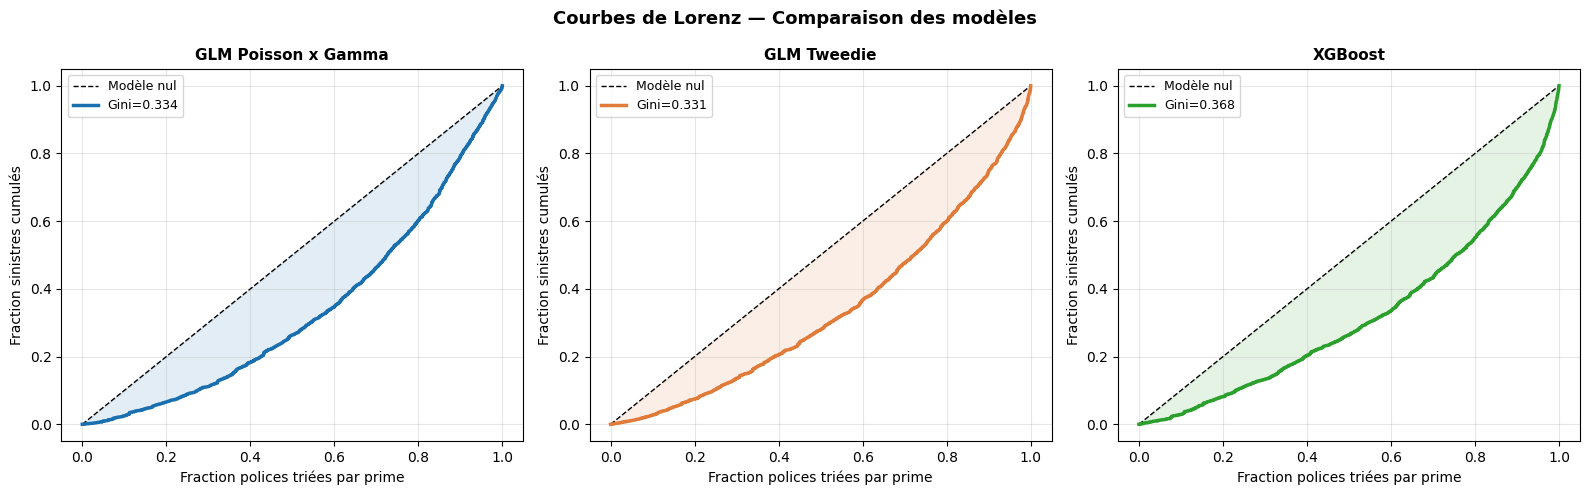

In [10]:
os.makedirs('figures', exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, pred) in zip(axes, models_preds.items()):
    color  = COLORS[name]
    order  = np.argsort(pred)
    yt, wt = y_test[order], w_test[order]
    cum_w  = np.concatenate([[0], np.cumsum(wt) / wt.sum()])
    cum_yw = np.concatenate([[0], np.cumsum(yt * wt) / (yt * wt).sum()])
    gini   = gini_coefficient(y_test, pred, w_test)

    ax.plot([0,1],[0,1],'k--',lw=1,label='Modèle nul')
    ax.fill_between(cum_w, cum_w, cum_yw, alpha=0.12, color=color)
    ax.plot(cum_w, cum_yw, color=color, lw=2.5, label=f'Gini={gini:.3f}')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_xlabel('Fraction polices triées par prime')
    ax.set_ylabel('Fraction sinistres cumulés')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.suptitle('Courbes de Lorenz — Comparaison des modèles', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/lorenz_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 9. Lift Curves

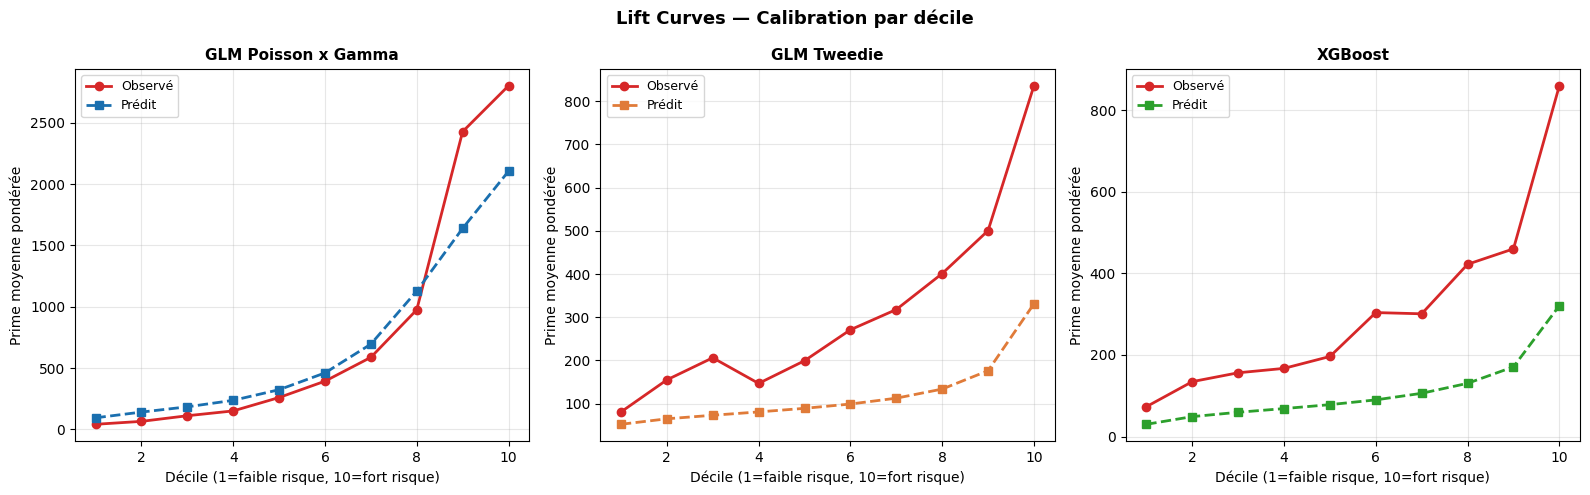

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
N = 10

for ax, (name, pred) in zip(axes, models_preds.items()):
    color = COLORS[name]
    try:
        bucket_labels = pd.qcut(pred, q=N, labels=False, duplicates='drop')
    except Exception:
        bucket_labels = pd.cut(pred, bins=N, labels=False)

    buckets_list, obs_list, pred_list = [], [], []
    for b in sorted(set(bucket_labels)):
        mask = bucket_labels == b
        if mask.sum() == 0: continue
        buckets_list.append(int(b) + 1)
        obs_list.append(y_test[mask].sum() / w_test[mask].sum())
        pred_list.append((pred[mask] * w_test[mask]).sum() / w_test[mask].sum())

    ax.plot(buckets_list, obs_list,  'o-', color=COLORS['ref'], lw=2, label='Observé')
    ax.plot(buckets_list, pred_list, 's--', color=color, lw=2, label='Prédit')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_xlabel(f'Décile (1=faible risque, {N}=fort risque)')
    ax.set_ylabel('Prime moyenne pondérée')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

plt.suptitle('Lift Curves — Calibration par décile', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/lift_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 10. Comparaison des Gini

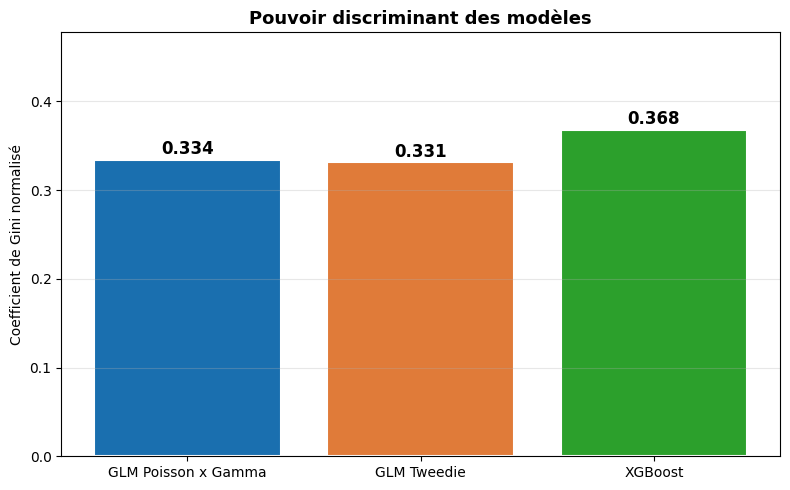

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ginis  = df_results['Gini'].values
models = df_results.index.tolist()
colors = [COLORS[m] for m in models]

bars = ax.bar(models, ginis, color=colors, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, ginis):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{val:.3f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('Coefficient de Gini normalisé')
ax.set_title('Pouvoir discriminant des modèles', fontsize=13, fontweight='bold')
ax.set_ylim(0, max(ginis) * 1.3)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('figures/gini_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## 11. Importance des variables — XGBoost

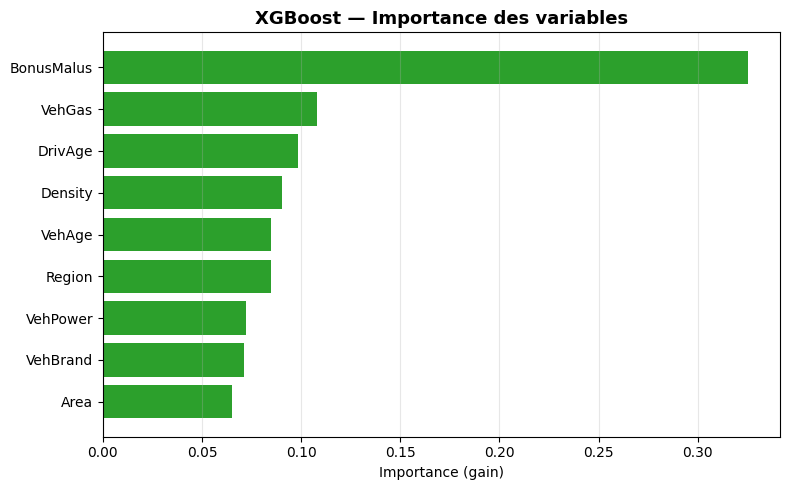

In [13]:
feat_names  = cat_cols + num_cols
importances = xgb_model.feature_importances_
idx         = np.argsort(importances)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh([feat_names[i] for i in idx], importances[idx], color=COLORS['XGBoost'])
ax.set_xlabel('Importance (gain)')
ax.set_title('XGBoost — Importance des variables', fontsize=13, fontweight='bold')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('figures/xgb_importance.png', dpi=150, bbox_inches='tight')
plt.show()


## 12. Tableau de synthèse

In [14]:
df_synthese = pd.DataFrame({
    'Modèle':                   ['GLM Poisson x Gamma', 'GLM Tweedie', 'XGBoost'],
    'Gini':                     df_results['Gini'].values,
    'RMSE':                     df_results['RMSE'].values,
    'MAE':                      df_results['MAE'].values,
    'Interprétabilité':         ['⭐⭐⭐ Très haute', '⭐⭐ Haute', '⭐ Faible'],
    'Fondement actuariel':      ['✅ Fréquence × Sévérité', '✅ Tweedie', '❌ Boîte noire'],
    'Conformité Solvabilité 2': ['✅ Compatible', '✅ Compatible', '⚠️ Difficile'],
}).set_index('Modèle')

print(df_synthese.to_string())


                       Gini     RMSE     MAE Interprétabilité     Fondement actuariel Conformité Solvabilité 2
Modèle                                                                                                        
GLM Poisson x Gamma  0.3342  1175.76  418.43   ⭐⭐⭐ Très haute  ✅ Fréquence × Sévérité             ✅ Compatible
GLM Tweedie          0.3313  1110.83  214.75         ⭐⭐ Haute               ✅ Tweedie             ✅ Compatible
XGBoost              0.3676  1108.84  204.30         ⭐ Faible           ❌ Boîte noire             ⚠️ Difficile


## 13. Conclusion

### Résultats quantitatifs

Le **coefficient de Gini** est la métrique centrale. Il mesure le pouvoir discriminant du tarif.

### Pourquoi GLM Poisson × Gamma ?

| Critère | GLM Poisson × Gamma | GLM Tweedie | XGBoost |
|---------|-------------------|-------------|---------|
| Interprétabilité | ✅ Coefficients explicites | ✅ Acceptable | ❌ Boîte noire |
| Séparation fréquence / sévérité | ✅ Explicite | ❌ Non | ❌ Non |
| Stabilité hors-échantillon | ✅ Régularisé | ✅ Régularisé | ⚠️ Surapprentissage |
| Conformité ACPR / EIOPA | ✅ | ✅ | ⚠️ |

> **Modèle retenu : GLM Poisson × Gamma**

---
*Notebook Laflame — branche main — MAM 4A Lyon 1*


In [15]:
# Sauvegarde
for base in ['../models', 'models']:
    if os.path.exists(base):
        with open(f'{base}/glm_tweedie.pkl', 'wb') as f:
            pickle.dump(glm_tweedie, f)
        with open(f'{base}/xgb_model.pkl', 'wb') as f:
            pickle.dump(xgb_model, f)
        df_results.to_csv(f'{base}/comparison_results.csv')
        print(f'Sauvegardé dans {base}/')
        break


Sauvegardé dans ../models/
